In [8]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import numpy as np
import torch

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import *

In [9]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [10]:
# Define the MPA model characteristics, Transmitter and Receiver size and position
# and the waveform to be used. 
times = torch.logspace(-5, -3, 32)
fwrTD = Forward.mpa(tx, rx, times, filterfunc=recfilter)


frqs = torch.logspace(3,6,51)
fwrFD = ForwardFD.mpa(tx, rx, frqs, filterfunc=recfilter)

c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [11]:
# Define the model parameters fopr the MPA model. It needs the following parameters:
# rho: resistivity of the layers in Ohm*m
# thickness: thickness of the layers in m
# tau: relaxation time of the layers in s
# c: Cole-Cole parameter of the layers (0 < c < 1)
# phi: porosity of the layers (0 < phi < 1)
# The model is defined as a list of layers, where the first layer is the top layer and the last layer is the bottom layer.


rho = torch.tensor([10,10], dtype=torch.double)
phi_max = torch.tensor([0.2,0.2], dtype=torch.double)
tau_phi = torch.tensor([1e-4, 1e-4], dtype=torch.double)
c = torch.ones(2, dtype=torch.double) * 0.6

thickness = torch.tensor([50], dtype=torch.double)

# The order of the variables are important. 
dbdt = fwrTD(rho, phi_max,tau_phi,c, thickness)
dbdf = fwrFD(rho, phi_max,tau_phi,c, thickness)

Text(0.5, 0, 'f (Hz)')

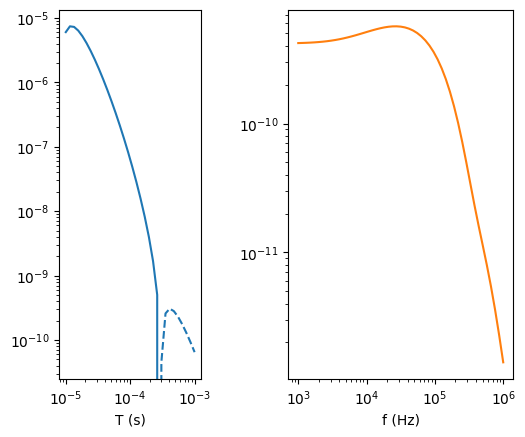

In [12]:
fig, axs = plt.subplots(1, 2)
axs[0].loglog(times, dbdt, label='MPA TD', color='C0')
axs[0].loglog(times, -dbdt, label='MPA TD', color='C0', linestyle='--')
axs[0].set_aspect('equal')
axs[1].loglog(frqs, torch.abs(dbdf), label='MPA FD', color='C1')
axs[0].set_xlabel('T (s)')
axs[1].set_xlabel('f (Hz)')

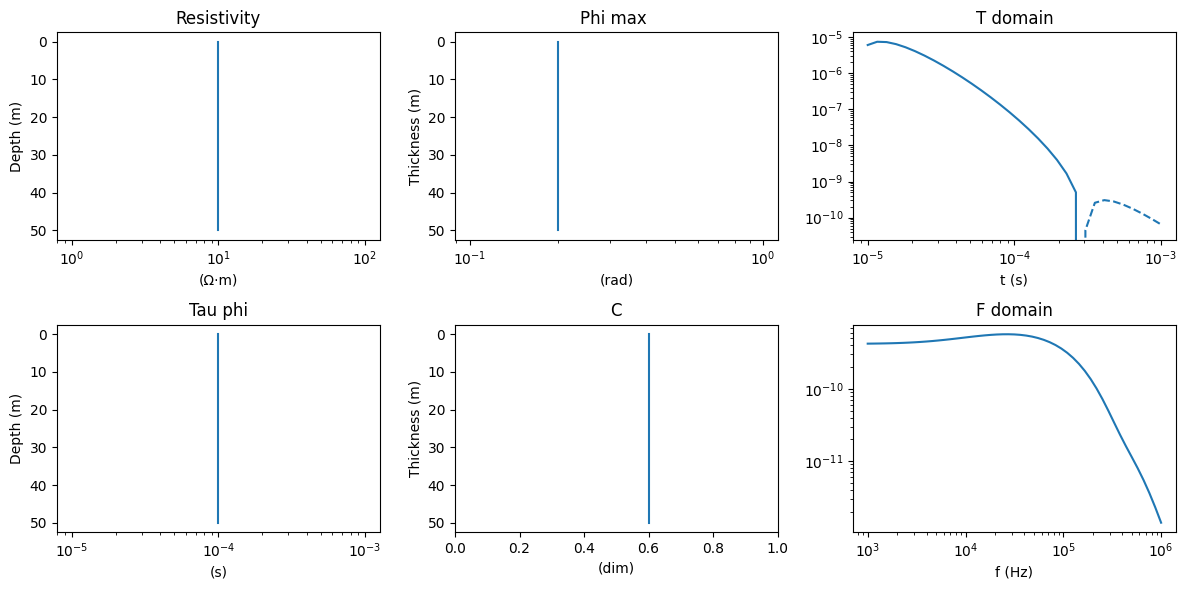

In [13]:
fig,axs = plt.subplots(2, 3, figsize=(12, 6))
axs[0,0].semilogx([rho[0].item(), rho[0].item()], [0, thickness[0].item()], color='C0', linestyle='-')

# Add labels and title for clarity
axs[0, 0].set_xlabel('(Ω·m)')
axs[0, 0].set_ylabel('Depth (m)')
axs[0, 0].set_title('Resistivity')
axs[0, 0].invert_yaxis()  # Optional: makes depth increase downward

axs[0,1].semilogx([phi_max[0].item(), phi_max[0].item()], [0, thickness[0].item()], color='C0', linestyle='-')
axs[0,1].set_xlabel('(rad)')
axs[0,1].set_ylabel('Thickness (m)')
axs[0,1].set_title('Phi max ')
axs[0,1].invert_yaxis()  # Optional: makes depth increase downward

axs[1,0].semilogx([tau_phi[0].item(), tau_phi[0].item()], [0, thickness[0].item()], color='C0', linestyle='-')
axs[1,0].set_xlabel('(s)')
axs[1,0].set_ylabel('Depth (m)')
axs[1,0].set_title('Tau phi')
axs[1,0].invert_yaxis()  # Optional: makes depth increase downward

axs[1,1].plot([c[0].item(), c[0].item()], [0, thickness[0].item()], color='C0', linestyle='-')
axs[1,1].set_xlim(0, 1)
axs[1,1].set_xlabel('(dim)')
axs[1,1].set_ylabel('Thickness (m)')
axs[1,1].set_title('C')
axs[1,1].invert_yaxis()  # Optional: makes depth increase downward

axs[0,2].loglog(times, dbdt, label='MPA TD', color='C0')
axs[0,2].loglog(times, -dbdt, label='MPA TD', color='C0', linestyle='--')
axs[0,2].set_xlabel('t (s)')
#axs[0,2].set_ylabel('dB/dt (T/s)')
axs[0,2].set_title('T domain')

axs[1,2].loglog(frqs, torch.abs(dbdf), label='MPA FD', color='C0')
axs[1,2].set_xlabel('f (Hz)')
#axs[1,2].set_ylabel('dB/df (T/Hz)')
axs[1,2].set_title('F domain')


plt.tight_layout()

In [ ]:

#mtrue = FewLayerMPA2([10, 10, 10], )
mtrue = inversion.MPA2(rho, phi_max, tau_phi, c, thickness)